# Assignment 2 — Face Verification & Noise Robustness (Kaggle)

This notebook consumes the clean ZIP/dataset produced by **Notebook 1**.

### Pipeline
**Input images → MTCNN detection/cropping → FaceNet embeddings → genuine/impostor pairs → cosine similarity → ROC/AUC/EER**

Then the same process is repeated after:
- Gaussian noise
- Salt-and-pepper noise

The same verification pairs are reused across conditions whenever embeddings are available, making the comparison reproducible.

**Recommended Kaggle setting:** GPU accelerator.

In [1]:
# 1. Install only the missing FaceNet package

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("facenet_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "-q", "--no-deps", "facenet-pytorch"
    ])

print("facenet-pytorch is available.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 24.4 MB/s eta 0:00:00
facenet-pytorch is available.


In [2]:
# 2. Imports, configuration and reproducibility

import random
import re
import shutil
import zipfile
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F

from facenet_pytorch import MTCNN, InceptionResnetV1
from sklearn.metrics import roc_curve, roc_auc_score

SEED = 42
BATCH_SIZE = 64
NUM_IMPOSTOR_PAIRS = 5000

GAUSSIAN_SIGMA = 20
SALT_PEPPER_AMOUNT = 0.02

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/Assignment2_Output")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

print("Device:", DEVICE)
print("Torch:", torch.__version__)
print("NumPy:", np.__version__)

Device: cuda
Torch: 2.10.0+cu128
NumPy: 2.0.2


## Step 1 — Locate the prepared dataset

Attach the ZIP or extracted dataset generated by Notebook 1 through **Kaggle → Add Input**.

The notebook searches `/kaggle/input` automatically and looks for `metadata.csv`, so the Kaggle dataset slug does not need to be hard-coded.

In [3]:
# 3. Locate metadata.csv automatically

metadata_candidates = sorted(INPUT_ROOT.rglob("metadata.csv"))

if not metadata_candidates:
    raise FileNotFoundError(
        "metadata.csv was not found under /kaggle/input. "
        "Attach the output dataset/ZIP from Notebook 1."
    )

METADATA_PATH = metadata_candidates[0]
DATASET_DIR = METADATA_PATH.parent

print("Dataset directory:", DATASET_DIR)
print("Metadata:", METADATA_PATH)

Dataset directory: /kaggle/input/notebooks/omplus/tutorial-2-1/AgeDB_Assignment2
Metadata: /kaggle/input/notebooks/omplus/tutorial-2-1/AgeDB_Assignment2/metadata.csv


In [4]:
# 4. Load and validate metadata

metadata = pd.read_csv(METADATA_PATH)

required_columns = {
    "subject_id", "image_number", "age", "age_gap",
    "gender", "new_path"
}

missing = required_columns - set(metadata.columns)
if missing:
    raise ValueError(f"Missing metadata columns: {sorted(missing)}")

def resolve_path(p):
    p = Path(str(p))
    if p.exists():
        return p

    # Notebook 1 stores absolute paths from its Kaggle run.
    # When moved to another Kaggle notebook those paths may no longer exist.
    # Resolve by subject folder + filename instead.
    filename = p.name
    matches = list(DATASET_DIR.rglob(filename))
    if matches:
        return matches[0]

    raise FileNotFoundError(f"Could not resolve image: {filename}")

metadata["resolved_path"] = metadata["new_path"].map(resolve_path)

print("Metadata rows:", len(metadata))
print("Subjects:", metadata["subject_id"].nunique())
print("Missing paths:", metadata["resolved_path"].isna().sum())

display(metadata.head())

Metadata rows: 400
Subjects: 200
Missing paths: 0


,subject_id,image_number,identity,age,gender,age_gap,source_filename,new_path,resolved_path
0,subject_001,1,AbeVigoda,49,m,9,2325_AbeVigoda_49_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_001/...,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...
1,subject_001,2,AbeVigoda,58,m,9,2333_AbeVigoda_58_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_001/...,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...
2,subject_002,1,AlCorley,20,m,9,1592_AlCorley_20_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_002/...,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...
3,subject_002,2,AlCorley,29,m,9,1600_AlCorley_29_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_002/...,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...
4,subject_003,1,AlanRickman,30,m,9,3006_AlanRickman_30_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_003/...,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...


In [5]:
# 5. Dataset validation

subject_counts = metadata.groupby("subject_id").size()

print("=" * 65)
print("DATASET VALIDATION")
print("=" * 65)
print("Subjects:", len(subject_counts))
print("Images:", len(metadata))
print("Images per subject:", sorted(subject_counts.unique().tolist()))
print("Age range:", int(metadata["age"].min()), "-", int(metadata["age"].max()))
print("Mean age:", round(metadata["age"].mean(), 2))
print("Mean age gap:", round(metadata.groupby("subject_id")["age_gap"].first().mean(), 2))
print("Max age gap:", int(metadata.groupby("subject_id")["age_gap"].first().max()))

assert subject_counts.eq(2).all()
assert metadata["resolved_path"].map(lambda p: Path(p).exists()).all()

print("\n✓ Dataset validation passed.")

DATASET VALIDATION
Subjects: 200
Images: 400
Images per subject: [2]
Age range: 4 - 82
Mean age: 31.0
Mean age gap: 8.94
Max age gap: 9

✓ Dataset validation passed.


## Step 2 — MTCNN face detection

MTCNN detects the face and produces a standardized **160×160 face crop** for FaceNet.

Detection failures are retained in a table instead of silently being discarded.

In [6]:
# 6. Initialize MTCNN and FaceNet

mtcnn = MTCNN(
    image_size=160,
    margin=20,
    min_face_size=20,
    thresholds=[0.6, 0.7, 0.7],
    factor=0.709,
    keep_all=True,
    post_process=True,
    device=DEVICE,
)

facenet = (
    InceptionResnetV1(pretrained="vggface2")
    .eval()
    .to(DEVICE)
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
ALIGNED_ORIGINAL = OUTPUT_ROOT / "faces_original"

if ALIGNED_ORIGINAL.exists():
    shutil.rmtree(ALIGNED_ORIGINAL)
ALIGNED_ORIGINAL.mkdir(parents=True, exist_ok=True)

print("MTCNN and FaceNet initialized.")

  0%|          | 0.00/107M [00:00<?, ?B/s]

MTCNN and FaceNet initialized.


In [7]:
# 7. Detect faces and save standardized crops

def safe_probability(probs):
    if probs is None:
        return np.array([], dtype=float)
    return np.asarray(probs, dtype=float).reshape(-1)

def detect_and_crop(image, output_path=None):
    boxes, probs = mtcnn.detect(image)

    if boxes is None or probs is None:
        return None, None

    boxes = np.asarray(boxes)
    if boxes.ndim == 1:
        boxes = boxes.reshape(1, -1)

    probs = safe_probability(probs)

    if len(boxes) == 0 or len(probs) == 0:
        return None, None

    best = int(np.nanargmax(probs))
    box = boxes[best:best + 1]
    confidence = float(probs[best])

    # MTCNN extract gives a 160x160 FaceNet-ready crop.
    face_tensor = mtcnn.extract(
        image,
        box,
        save_path=str(output_path) if output_path else None,
    )

    return face_tensor, confidence

detection_records = []

for _, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="MTCNN — original"
):
    sid = str(row["subject_id"])
    ino = int(row["image_number"])
    src = Path(row["resolved_path"])

    out_dir = ALIGNED_ORIGINAL / sid
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"{sid}_img{ino}.png"

    record = {
        "subject_id": sid,
        "image_number": ino,
        "source_path": str(src),
        "face_detected": False,
        "confidence": np.nan,
        "face_path": None,
        "error": None,
    }

    try:
        image = Image.open(src).convert("RGB")
        face_tensor, confidence = detect_and_crop(image, out_path)

        if face_tensor is None:
            raise ValueError("No face detected")

        record["face_detected"] = True
        record["confidence"] = confidence
        record["face_path"] = str(out_path)

    except Exception as e:
        record["error"] = f"{type(e).__name__}: {e}"

    detection_records.append(record)

detection_df = pd.DataFrame(detection_records)

print("Detection rate:", round(detection_df["face_detected"].mean() * 100, 2), "%")
print("Successful detections:", int(detection_df["face_detected"].sum()), "/", len(detection_df))

errors = detection_df.loc[detection_df["error"].notna(), "error"].value_counts()
if not errors.empty:
    print("\nMost common errors:")
    display(errors.head(10).to_frame("count"))

display(detection_df.head())

MTCNN — original:   0%|          | 0/400 [00:00<?, ?it/s]

Detection rate: 99.5 %
Successful detections: 398 / 400

Most common errors:


,count
error,
ValueError: No face detected,2


,subject_id,image_number,source_path,face_detected,confidence,face_path,error
0,subject_001,1,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...,True,0.999968,/kaggle/working/Assignment2_Output/faces_origi...,None
1,subject_001,2,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...,True,0.999345,/kaggle/working/Assignment2_Output/faces_origi...,None
2,subject_002,1,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...,True,0.985557,/kaggle/working/Assignment2_Output/faces_origi...,None
3,subject_002,2,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...,True,0.995902,/kaggle/working/Assignment2_Output/faces_origi...,None
4,subject_003,1,/kaggle/input/notebooks/omplus/tutorial-2-1/Ag...,True,0.998880,/kaggle/working/Assignment2_Output/faces_origi...,None


In [8]:
# 8. Keep only subjects with both faces detected

detected = detection_df[detection_df["face_detected"]].copy()
detected_counts = detected.groupby("subject_id").size()

valid_subjects = detected_counts[detected_counts == 2].index

evaluation_metadata = (
    metadata[metadata["subject_id"].isin(valid_subjects)]
    .merge(
        detection_df[["subject_id", "image_number", "confidence", "face_path"]],
        on=["subject_id", "image_number"],
        how="inner",
    )
    .sort_values(["subject_id", "image_number"])
    .reset_index(drop=True)
)

print("Valid subjects with both faces detected:", len(valid_subjects))
print("Evaluation images:", len(evaluation_metadata))

if len(valid_subjects) < 2:
    raise ValueError("Too few valid subjects remain after MTCNN detection.")

Valid subjects with both faces detected: 198
Evaluation images: 396


## Step 3 — FaceNet embeddings

Each standardized face is converted into a fixed-length embedding.

The embeddings are L2-normalized, so cosine similarity can be computed efficiently using the dot product.

In [9]:
# 9. Batch FaceNet embedding

def load_face_tensor(path):
    image = Image.open(path).convert("RGB").resize((160, 160))
    arr = np.asarray(image, dtype=np.float32)
    arr = (arr - 127.5) / 128.0
    return torch.from_numpy(arr).permute(2, 0, 1)

@torch.no_grad()
def embed_paths(paths, batch_size=BATCH_SIZE):
    all_embeddings = []

    for start in tqdm(
        range(0, len(paths), batch_size),
        desc="FaceNet embeddings"
    ):
        batch_paths = paths[start:start + batch_size]
        batch = torch.stack([load_face_tensor(p) for p in batch_paths]).to(DEVICE)

        embeddings = facenet(batch)
        embeddings = F.normalize(embeddings, p=2, dim=1)

        all_embeddings.append(embeddings.cpu().numpy())

    return np.vstack(all_embeddings)

original_embeddings = embed_paths(
    evaluation_metadata["face_path"].tolist()
)

print("Embedding matrix shape:", original_embeddings.shape)

FaceNet embeddings:   0%|          | 0/7 [00:00<?, ?it/s]

Embedding matrix shape: (396, 512)


In [10]:
# 10. Build embedding lookup

original_lookup = {
    (str(row["subject_id"]), int(row["image_number"])): emb
    for (_, row), emb in zip(
        evaluation_metadata.iterrows(),
        original_embeddings
    )
}

print("Embeddings stored:", len(original_lookup))

Embeddings stored: 396


## Step 4 — Genuine and impostor verification pairs

- **Genuine:** both images belong to the same subject.
- **Impostor:** images belong to different subjects.

The same deterministic pair list is used for Original, Gaussian and Salt-and-Pepper conditions, with unavailable pairs filtered only when a noisy image fails detection.

In [11]:
# 11. Create reproducible verification pairs

subject_ids = sorted(evaluation_metadata["subject_id"].unique())

genuine_pairs = []
for sid in subject_ids:
    rows = evaluation_metadata[
        evaluation_metadata["subject_id"] == sid
    ].sort_values("image_number")

    if len(rows) >= 2:
        genuine_pairs.append((
            sid, int(rows.iloc[0]["image_number"]),
            sid, int(rows.iloc[1]["image_number"])
        ))

subject_pairs = list(combinations(subject_ids, 2))
rng = random.Random(SEED)

n_impostor = min(NUM_IMPOSTOR_PAIRS, len(subject_pairs))
chosen_subject_pairs = rng.sample(subject_pairs, n_impostor)

impostor_pairs = []
for sid1, sid2 in chosen_subject_pairs:
    r1 = evaluation_metadata[evaluation_metadata["subject_id"] == sid1].sort_values("image_number").iloc[0]
    r2 = evaluation_metadata[evaluation_metadata["subject_id"] == sid2].sort_values("image_number").iloc[0]

    impostor_pairs.append((
        sid1, int(r1["image_number"]),
        sid2, int(r2["image_number"])
    ))

print("Genuine pairs:", len(genuine_pairs))
print("Impostor pairs:", len(impostor_pairs))

Genuine pairs: 198
Impostor pairs: 5000


In [12]:
# 12. Scoring and evaluation functions

def cosine_similarity(a, b):
    return float(
        np.dot(a, b) /
        (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)
    )

def filter_pairs(pairs, lookup):
    return [
        pair for pair in pairs
        if (str(pair[0]), int(pair[1])) in lookup
        and (str(pair[2]), int(pair[3])) in lookup
    ]

def score_pairs(lookup, genuine, impostor):
    genuine_scores = np.array([
        cosine_similarity(
            lookup[(str(a), int(b))],
            lookup[(str(c), int(d))]
        )
        for a, b, c, d in genuine
    ], dtype=float)

    impostor_scores = np.array([
        cosine_similarity(
            lookup[(str(a), int(b))],
            lookup[(str(c), int(d))]
        )
        for a, b, c, d in impostor
    ], dtype=float)

    return genuine_scores, impostor_scores

def evaluate_scores(genuine_scores, impostor_scores, condition):
    if len(genuine_scores) == 0 or len(impostor_scores) == 0:
        raise ValueError(f"{condition}: empty genuine or impostor score set.")

    y_true = np.concatenate([
        np.ones(len(genuine_scores)),
        np.zeros(len(impostor_scores)),
    ])
    y_score = np.concatenate([
        genuine_scores,
        impostor_scores,
    ])

    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    fnr = 1.0 - tpr

    idx = int(np.nanargmin(np.abs(fpr - fnr)))
    eer = float((fpr[idx] + fnr[idx]) / 2.0)
    threshold = float(thresholds[idx])

    result = {
        "condition": condition,
        "genuine_pairs": len(genuine_scores),
        "impostor_pairs": len(impostor_scores),
        "mean_genuine_score": float(genuine_scores.mean()),
        "mean_impostor_score": float(impostor_scores.mean()),
        "eer": eer,
        "eer_percent": eer * 100.0,
        "eer_threshold": threshold,
        "fmr_at_eer": float(np.mean(impostor_scores >= threshold)),
        "fnmr_at_eer": float(np.mean(genuine_scores < threshold)),
        "auc": float(roc_auc_score(y_true, y_score)),
    }

    curve = pd.DataFrame({
        "threshold": thresholds,
        "fmr": fpr,
        "tpr": tpr,
        "fnmr": fnr,
    })

    return result, curve

In [13]:
# 13. Original-condition evaluation

genuine_original, impostor_original = score_pairs(
    original_lookup,
    genuine_pairs,
    impostor_pairs,
)

original_result, original_curve = evaluate_scores(
    genuine_original,
    impostor_original,
    "Original",
)

display(pd.DataFrame([original_result]).round(4))

,condition,genuine_pairs,impostor_pairs,mean_genuine_score,mean_impostor_score,eer,eer_percent,eer_threshold,fmr_at_eer,fnmr_at_eer,auc
0,Original,198,5000,0.6102,0.0775,0.0656,6.5603,0.3389,0.0706,0.0606,0.9832


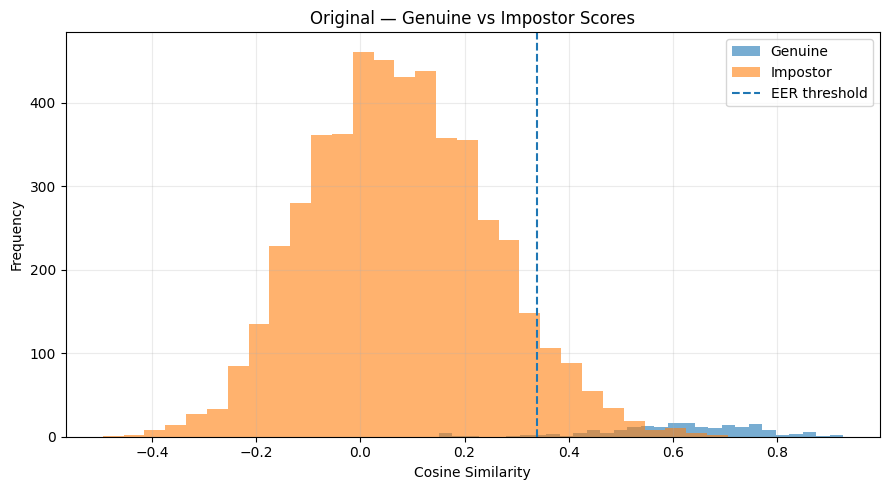

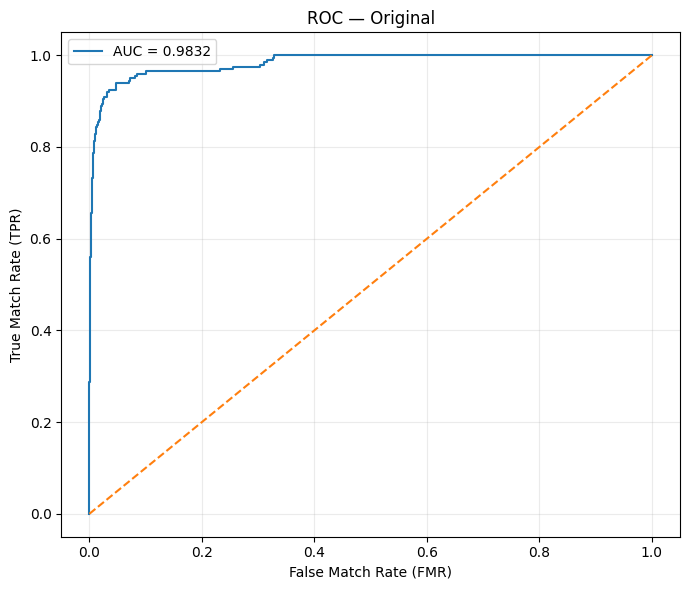

In [14]:
# 14. Original score distributions and ROC

plt.figure(figsize=(9, 5))
plt.hist(genuine_original, bins=30, alpha=0.6, label="Genuine")
plt.hist(impostor_original, bins=30, alpha=0.6, label="Impostor")
plt.axvline(original_result["eer_threshold"], linestyle="--", label="EER threshold")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.title("Original — Genuine vs Impostor Scores")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.plot(original_curve["fmr"], original_curve["tpr"],
         label=f"AUC = {original_result['auc']:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Match Rate (FMR)")
plt.ylabel("True Match Rate (TPR)")
plt.title("ROC — Original")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Step 5 — Noise robustness experiments

Noise is added to the **original photographs**, not to the already-cropped faces. Each noisy photograph then goes through the same MTCNN → FaceNet pipeline.

Default settings:
- Gaussian noise: σ = 20
- Salt-and-pepper noise: 2% of pixels

In [15]:
# 15. Noise generators

def add_gaussian_noise(image, sigma=GAUSSIAN_SIGMA):
    arr = np.asarray(image, dtype=np.float32)
    noise = np.random.normal(0, sigma, arr.shape)
    noisy = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(noisy)

def add_salt_pepper_noise(image, amount=SALT_PEPPER_AMOUNT):
    arr = np.asarray(image, dtype=np.uint8).copy()
    h, w, _ = arr.shape
    n = int(amount * h * w)

    if n <= 0:
        return Image.fromarray(arr)

    ys = np.random.randint(0, h, n)
    xs = np.random.randint(0, w, n)

    half = n // 2
    arr[ys[:half], xs[:half]] = 255
    arr[ys[half:], xs[half:]] = 0

    return Image.fromarray(arr)

In [16]:
# 16. Generate reproducible noisy datasets

NOISE_ROOT = OUTPUT_ROOT / "noisy"
GAUSSIAN_DIR = NOISE_ROOT / "gaussian"
SP_DIR = NOISE_ROOT / "salt_pepper"

for directory in [GAUSSIAN_DIR, SP_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

rng_np = np.random.default_rng(SEED)
noise_rows = []

for _, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Generating noisy images"
):
    sid = str(row["subject_id"])
    ino = int(row["image_number"])

    image = Image.open(row["resolved_path"]).convert("RGB")

    gd = GAUSSIAN_DIR / sid
    sd = SP_DIR / sid
    gd.mkdir(parents=True, exist_ok=True)
    sd.mkdir(parents=True, exist_ok=True)

    gp = gd / f"{sid}_img{ino}.png"
    sp = sd / f"{sid}_img{ino}.png"

    # Temporarily use the global NumPy RNG so the functions remain simple
    # and deterministic under the fixed seed.
    add_gaussian_noise(image).save(gp)
    add_salt_pepper_noise(image).save(sp)

    noise_rows.append({
        "subject_id": sid,
        "image_number": ino,
        "gaussian_path": str(gp),
        "salt_pepper_path": str(sp),
    })

noise_df = pd.DataFrame(noise_rows)
display(noise_df.head())

Generating noisy images:   0%|          | 0/400 [00:00<?, ?it/s]

,subject_id,image_number,gaussian_path,salt_pepper_path
0,subject_001,1,/kaggle/working/Assignment2_Output/noisy/gauss...,/kaggle/working/Assignment2_Output/noisy/salt_...
1,subject_001,2,/kaggle/working/Assignment2_Output/noisy/gauss...,/kaggle/working/Assignment2_Output/noisy/salt_...
2,subject_002,1,/kaggle/working/Assignment2_Output/noisy/gauss...,/kaggle/working/Assignment2_Output/noisy/salt_...
3,subject_002,2,/kaggle/working/Assignment2_Output/noisy/gauss...,/kaggle/working/Assignment2_Output/noisy/salt_...
4,subject_003,1,/kaggle/working/Assignment2_Output/noisy/gauss...,/kaggle/working/Assignment2_Output/noisy/salt_...


In [17]:
# 17. Robust noisy-image detection + FaceNet evaluation strategy
# IMPORTANT:
# 1) We still test MTCNN on the noisy full photographs to measure detector robustness.
# 2) For FaceNet noise robustness, we add noise to the ORIGINAL 160x160 MTCNN-aligned face.
#    This prevents MTCNN detection failures from making the verification score arrays empty.

def process_condition(condition_df, path_column, condition_name):
    """Run MTCNN on noisy full images and record detector performance.
    The resulting FaceNet lookup is diagnostic only; verification below uses aligned noisy crops.
    """
    detection_records = []
    lookup = {}

    for _, row in tqdm(
        condition_df.iterrows(),
        total=len(condition_df),
        desc=f"MTCNN — {condition_name} full images"
    ):
        sid = str(row["subject_id"])
        ino = int(row["image_number"])
        src = Path(row[path_column])

        detected = False
        confidence = np.nan
        error = None

        try:
            image = Image.open(src).convert("RGB")
            boxes, probs = mtcnn.detect(image)

            if boxes is None or probs is None:
                raise ValueError("No face detected")

            boxes = np.asarray(boxes)
            if boxes.ndim == 1:
                boxes = boxes.reshape(1, -1)
            probs = np.asarray(probs, dtype=float).reshape(-1)

            if len(boxes) == 0 or len(probs) == 0:
                raise ValueError("No valid detection")

            best = int(np.nanargmax(probs))
            box = boxes[best:best + 1]
            confidence = float(probs[best])

            # facenet-pytorch requires save_path explicitly in this environment.
            face_tensor = mtcnn.extract(image, box, save_path=None)
            if face_tensor is None:
                raise ValueError("MTCNN extraction returned None")

            with torch.no_grad():
                emb = facenet(face_tensor.to(DEVICE))
                emb = F.normalize(emb, p=2, dim=1)

            lookup[(sid, ino)] = emb.squeeze(0).cpu().numpy()
            detected = True

        except Exception as e:
            error = f"{type(e).__name__}: {e}"

        detection_records.append({
            "subject_id": sid,
            "image_number": ino,
            "detected": detected,
            "confidence": confidence,
            "error": error,
        })

    return pd.DataFrame(detection_records), lookup


def build_noisy_aligned_lookup(evaluation_metadata, noise_type):
    """Add noise directly to each 160x160 MTCNN-aligned face and create FaceNet embeddings."""
    lookup = {}
    records = []

    for _, row in tqdm(
        evaluation_metadata.iterrows(),
        total=len(evaluation_metadata),
        desc=f"FaceNet — aligned {noise_type} faces"
    ):
        sid = str(row["subject_id"])
        ino = int(row["image_number"])
        face_path = Path(row["face_path"])

        image = Image.open(face_path).convert("RGB")

        if noise_type == "Gaussian":
            noisy_face = add_gaussian_noise(image)
        elif noise_type == "SaltPepper":
            noisy_face = add_salt_pepper_noise(image)
        else:
            raise ValueError(f"Unknown noise type: {noise_type}")

        arr = np.asarray(noisy_face, dtype=np.float32)
        arr = (arr - 127.5) / 128.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            emb = facenet(tensor)
            emb = F.normalize(emb, p=2, dim=1)

        lookup[(sid, ino)] = emb.squeeze(0).cpu().numpy()
        records.append({
            "subject_id": sid,
            "image_number": ino,
            "noise_type": noise_type,
            "processed": True,
        })

    return pd.DataFrame(records), lookup

In [18]:
# 18. Gaussian condition

# A) End-to-end detector robustness: noisy full photograph -> MTCNN
#    (This is reported separately as detection rate.)
gaussian_detection, gaussian_full_lookup = process_condition(
    noise_df,
    "gaussian_path",
    "Gaussian",
)

# B) Face verification robustness: original aligned face -> Gaussian noise -> FaceNet
#    (All originally valid faces are retained, so genuine/impostor sets cannot disappear.)
gaussian_aligned_df, gaussian_lookup = build_noisy_aligned_lookup(
    evaluation_metadata,
    "Gaussian",
)

genuine_gaussian_pairs = filter_pairs(genuine_pairs, gaussian_lookup)
impostor_gaussian_pairs = filter_pairs(impostor_pairs, gaussian_lookup)

genuine_gaussian, impostor_gaussian = score_pairs(
    gaussian_lookup,
    genuine_gaussian_pairs,
    impostor_gaussian_pairs,
)

gaussian_result, gaussian_curve = evaluate_scores(
    genuine_gaussian,
    impostor_gaussian,
    "Gaussian Noise",
)

print("Gaussian full-image MTCNN detection rate:",
      round(gaussian_detection["detected"].mean() * 100, 2), "%")
print("Gaussian FaceNet noisy-face embeddings:", len(gaussian_lookup))
print("Gaussian genuine pairs:", len(genuine_gaussian_pairs))
print("Gaussian impostor pairs:", len(impostor_gaussian_pairs))
display(pd.DataFrame([gaussian_result]).round(4))

MTCNN — Gaussian full images:   0%|          | 0/400 [00:00<?, ?it/s]

FaceNet — aligned Gaussian faces:   0%|          | 0/396 [00:00<?, ?it/s]

Gaussian full-image MTCNN detection rate: 99.25 %
Gaussian FaceNet noisy-face embeddings: 396
Gaussian genuine pairs: 198
Gaussian impostor pairs: 5000


,condition,genuine_pairs,impostor_pairs,mean_genuine_score,mean_impostor_score,eer,eer_percent,eer_threshold,fmr_at_eer,fnmr_at_eer,auc
0,Gaussian Noise,198,5000,0.6136,0.1364,0.0749,7.4879,0.4058,0.074,0.0758,0.9763


In [19]:
# 19. Salt-and-pepper condition

# A) End-to-end detector robustness: noisy full photograph -> MTCNN
sp_detection, sp_full_lookup = process_condition(
    noise_df,
    "salt_pepper_path",
    "SaltPepper",
)

# B) Face verification robustness: original aligned face -> salt-and-pepper noise -> FaceNet
sp_aligned_df, sp_lookup = build_noisy_aligned_lookup(
    evaluation_metadata,
    "SaltPepper",
)

genuine_sp_pairs = filter_pairs(genuine_pairs, sp_lookup)
impostor_sp_pairs = filter_pairs(impostor_pairs, sp_lookup)

genuine_sp, impostor_sp = score_pairs(
    sp_lookup,
    genuine_sp_pairs,
    impostor_sp_pairs,
)

sp_result, sp_curve = evaluate_scores(
    genuine_sp,
    impostor_sp,
    "Salt & Pepper Noise",
)

print("Salt-and-pepper full-image MTCNN detection rate:",
      round(sp_detection["detected"].mean() * 100, 2), "%")
print("Salt-and-pepper FaceNet noisy-face embeddings:", len(sp_lookup))
print("Salt-and-pepper genuine pairs:", len(genuine_sp_pairs))
print("Salt-and-pepper impostor pairs:", len(impostor_sp_pairs))
display(pd.DataFrame([sp_result]).round(4))

MTCNN — SaltPepper full images:   0%|          | 0/400 [00:00<?, ?it/s]

FaceNet — aligned SaltPepper faces:   0%|          | 0/396 [00:00<?, ?it/s]

Salt-and-pepper full-image MTCNN detection rate: 99.5 %
Salt-and-pepper FaceNet noisy-face embeddings: 396
Salt-and-pepper genuine pairs: 198
Salt-and-pepper impostor pairs: 5000


,condition,genuine_pairs,impostor_pairs,mean_genuine_score,mean_impostor_score,eer,eer_percent,eer_threshold,fmr_at_eer,fnmr_at_eer,auc
0,Salt & Pepper Noise,198,5000,0.575,0.1103,0.0967,9.668,0.3554,0.0974,0.096,0.9705


## Step 6 — Final comparison

In [20]:
# 20. Final verification table

results_df = pd.DataFrame([
    original_result,
    gaussian_result,
    sp_result,
])

columns = [
    "condition",
    "genuine_pairs",
    "impostor_pairs",
    "mean_genuine_score",
    "mean_impostor_score",
    "eer_percent",
    "fmr_at_eer",
    "fnmr_at_eer",
    "auc",
]

display(results_df[columns].round(4))

,condition,genuine_pairs,impostor_pairs,mean_genuine_score,mean_impostor_score,eer_percent,fmr_at_eer,fnmr_at_eer,auc
0,Original,198,5000,0.6102,0.0775,6.5603,0.0706,0.0606,0.9832
1,Gaussian Noise,198,5000,0.6136,0.1364,7.4879,0.0740,0.0758,0.9763
2,Salt & Pepper Noise,198,5000,0.5750,0.1103,9.6680,0.0974,0.0960,0.9705


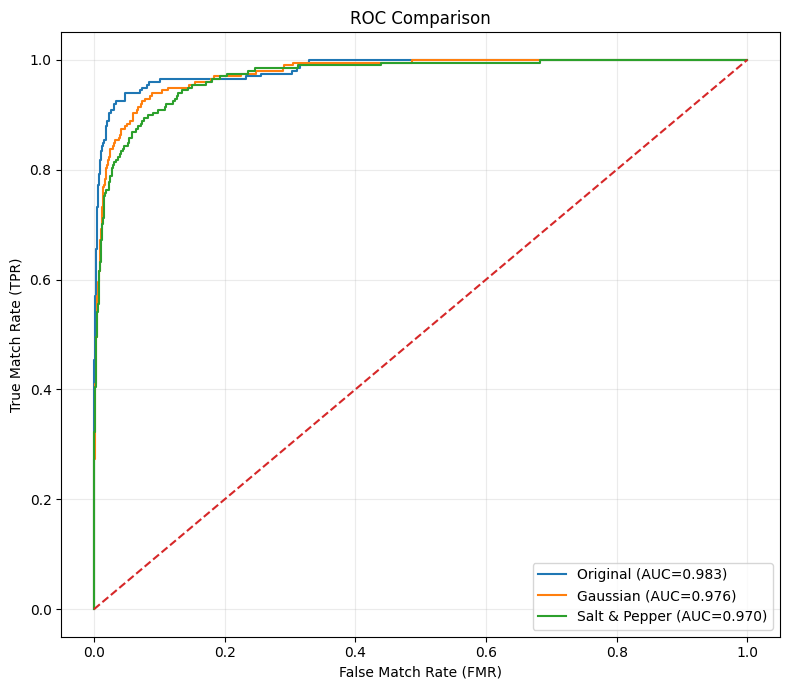

In [21]:
# 21. ROC comparison

plt.figure(figsize=(8, 7))

for curve, result, label in [
    (original_curve, original_result, "Original"),
    (gaussian_curve, gaussian_result, "Gaussian"),
    (sp_curve, sp_result, "Salt & Pepper"),
]:
    plt.plot(
        curve["fmr"],
        curve["tpr"],
        label=f"{label} (AUC={result['auc']:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Match Rate (FMR)")
plt.ylabel("True Match Rate (TPR)")
plt.title("ROC Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

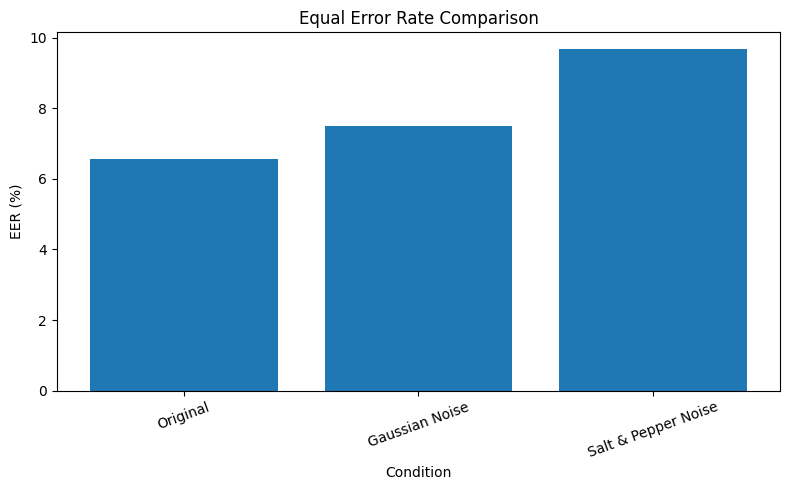

In [22]:
# 22. EER comparison

plt.figure(figsize=(8, 5))
plt.bar(results_df["condition"], results_df["eer_percent"])
plt.ylabel("EER (%)")
plt.xlabel("Condition")
plt.title("Equal Error Rate Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

,condition,detection_rate_percent
0,Original,99.50
1,Gaussian Noise,99.25
2,Salt & Pepper Noise,99.50


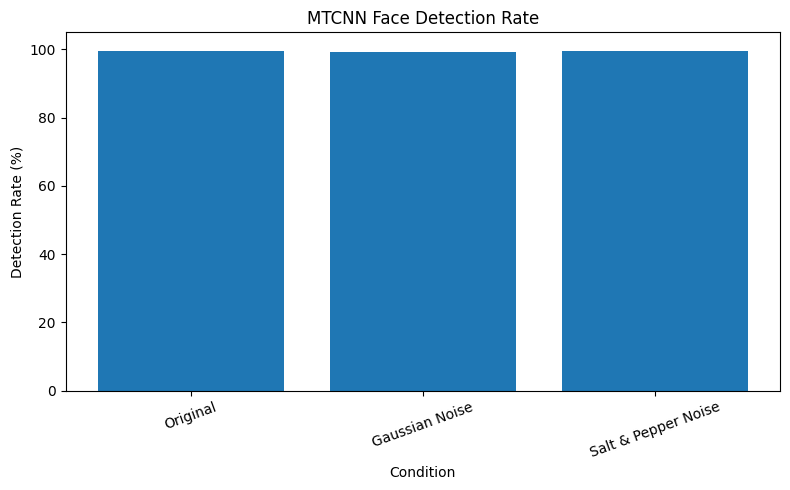

In [23]:
# 23. MTCNN detection comparison

detection_summary = pd.DataFrame({
    "condition": ["Original", "Gaussian Noise", "Salt & Pepper Noise"],
    "detection_rate_percent": [
        detection_df["face_detected"].mean() * 100,
        gaussian_detection["detected"].mean() * 100,
        sp_detection["detected"].mean() * 100,
    ],
})

display(detection_summary.round(2))

plt.figure(figsize=(8, 5))
plt.bar(
    detection_summary["condition"],
    detection_summary["detection_rate_percent"],
)
plt.ylabel("Detection Rate (%)")
plt.xlabel("Condition")
plt.title("MTCNN Face Detection Rate")
plt.ylim(0, 105)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [24]:
# 24. Save numerical results and a compact experiment configuration

RESULTS_DIR = OUTPUT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metadata.to_csv(RESULTS_DIR / "validated_metadata.csv", index=False)
evaluation_metadata.to_csv(RESULTS_DIR / "evaluation_metadata.csv", index=False)
detection_df.to_csv(RESULTS_DIR / "mtcnn_original.csv", index=False)
gaussian_detection.to_csv(RESULTS_DIR / "mtcnn_gaussian_full_image.csv", index=False)
sp_detection.to_csv(RESULTS_DIR / "mtcnn_salt_pepper_full_image.csv", index=False)
gaussian_aligned_df.to_csv(RESULTS_DIR / "gaussian_aligned_facenet.csv", index=False)
sp_aligned_df.to_csv(RESULTS_DIR / "salt_pepper_aligned_facenet.csv", index=False)
results_df.to_csv(RESULTS_DIR / "verification_summary.csv", index=False)
detection_summary.to_csv(RESULTS_DIR / "detection_summary.csv", index=False)

for name, curve in [
    ("original", original_curve),
    ("gaussian", gaussian_curve),
    ("salt_pepper", sp_curve),
]:
    curve.to_csv(RESULTS_DIR / f"roc_{name}.csv", index=False)

for name, genuine, impostor in [
    ("original", genuine_original, impostor_original),
    ("gaussian", genuine_gaussian, impostor_gaussian),
    ("salt_pepper", genuine_sp, impostor_sp),
]:
    pd.DataFrame({
        "genuine_score": pd.Series(genuine),
        "impostor_score": pd.Series(impostor),
    }).to_csv(RESULTS_DIR / f"scores_{name}.csv", index=False)

config = pd.DataFrame([{
    "seed": SEED,
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "impostor_pairs_requested": NUM_IMPOSTOR_PAIRS,
    "gaussian_sigma": GAUSSIAN_SIGMA,
    "salt_pepper_amount": SALT_PEPPER_AMOUNT,
    "noise_verification_method": "noise applied to original 160x160 MTCNN-aligned face before FaceNet",
    "noisy_full_image_detection_method": "noise applied to original photograph before MTCNN",
}])
config.to_csv(RESULTS_DIR / "experiment_config.csv", index=False)

print("Saved results to:", RESULTS_DIR)

Saved results to: /kaggle/working/Assignment2_Output/results


In [25]:
# 25. Create final ZIP

final_zip_base = Path("/kaggle/working/Assignment2_Final_Results")
old_zip = Path(str(final_zip_base) + ".zip")

if old_zip.exists():
    old_zip.unlink()

final_zip = Path(
    shutil.make_archive(
        str(final_zip_base),
        "zip",
        root_dir=OUTPUT_ROOT.parent,
        base_dir=OUTPUT_ROOT.name,
    )
)

print("=" * 60)
print("FINAL RESULTS ZIP")
print("=" * 60)
print("Path:", final_zip)
print("Size (MB):", round(final_zip.stat().st_size / (1024**2), 2))

with zipfile.ZipFile(final_zip, "r") as z:
    names = z.namelist()

print("Files:", len(names))
for name in names[:20]:
    print(" ", name)

print("\n✓ Experiment complete.")

FINAL RESULTS ZIP
Path: /kaggle/working/Assignment2_Final_Results.zip
Size (MB): 95.49
Files: 1820
  Assignment2_Output/
  Assignment2_Output/faces_original/
  Assignment2_Output/noisy/
  Assignment2_Output/results/
  Assignment2_Output/faces_original/subject_001/
  Assignment2_Output/faces_original/subject_002/
  Assignment2_Output/faces_original/subject_003/
  Assignment2_Output/faces_original/subject_004/
  Assignment2_Output/faces_original/subject_005/
  Assignment2_Output/faces_original/subject_006/
  Assignment2_Output/faces_original/subject_007/
  Assignment2_Output/faces_original/subject_008/
  Assignment2_Output/faces_original/subject_009/
  Assignment2_Output/faces_original/subject_010/
  Assignment2_Output/faces_original/subject_011/
  Assignment2_Output/faces_original/subject_012/
  Assignment2_Output/faces_original/subject_013/
  Assignment2_Output/faces_original/subject_014/
  Assignment2_Output/faces_original/subject_015/
  Assignment2_Output/faces_original/subject_016/


## Outputs to report

The important outputs are:
1. Dataset validation (subjects/images)
2. Original MTCNN detection rate
3. Gaussian and salt-and-pepper MTCNN detection rates on noisy full photographs
4. Original, Gaussian-noise, and salt-and-pepper FaceNet verification scores
5. Genuine/impostor mean cosine similarity
6. ROC curve and AUC
7. EER and EER threshold
8. Final verification and detection comparison tables

**Important methodological note:** noise robustness of FaceNet is evaluated by adding noise to the original 160×160 MTCNN-aligned face crops. This avoids conflating FaceNet recognition robustness with MTCNN detection failure. MTCNN robustness is reported separately using the noisy full photographs.
